O atraso na entrega derruba a nota de avaliação?

Sim. Pedidos entregues no prazo têm nota média de 4,29; os atrasados, 2,27. A queda começa logo nos primeiros dias (3,29 com 1 a 3 dias de atraso) e, a partir de 4 dias, mais de dois terços das avaliações são de 1 ou 2 estrelas.

In [1]:
import sys
from pathlib import Path
raiz_projeto = Path().resolve().parent
if str(raiz_projeto) not in sys.path:
    sys.path.append(str(raiz_projeto))

import pandas as pd
from sqlalchemy import create_engine
import matplotlib.pyplot as plt
import seaborn as sns
from src import config
sns.set_theme(style="whitegrid")


engine = create_engine(config.DATABASE_URL)

In [2]:
query = """ WITH avaliacoes AS (
    SELECT order_id, AVG(review_score) AS review_score
    FROM order_reviews
    GROUP BY order_id 
)

SELECT
    o.order_id,
    a.review_score,
    (o.order_delivered_customer_date::date
     - o.order_estimated_delivery_date::date) AS dias_atraso
FROM orders o
JOIN avaliacoes a USING (order_id)
WHERE o.order_status = 'delivered'
  AND o.order_delivered_customer_date IS NOT NULL;
    """

df = pd.read_sql(query, engine)
df.head()

,order_id,review_score,dias_atraso
0,738c536e3bfc3c99dddffed112e89349,5.0,-8
1,c0b4d042df532a3a84b95e89bf2a53c1,4.0,-10
2,c8bc8f1025acaa48d5be4ea4c11c88a3,5.0,-18
3,8d40f6aeb11aa6d03d17b3fa59b14fbe,2.0,-9
4,88ac33fac1d5d735fecc0f5fca69b0b0,5.0,-8


In [3]:
df["atrasado"] = df["dias_atraso"] > 0

resumo = (
    df.groupby("atrasado")["review_score"]
      .agg(pedidos="count", nota_media="mean")
      .round(2)
)
resumo["pct_pedidos"] = (resumo["pedidos"] / resumo["pedidos"].sum() * 100).round(1)
resumo

,pedidos,nota_media,pct_pedidos
atrasado,,,
False,89443,4.29,93.3
True,6381,2.27,6.7


In [4]:
faixas = pd.cut(
    df["dias_atraso"],
    bins=[-float("inf"), 0, 3, 7, 14, float("inf")],
    labels=["No prazo", "1-3 dias", "4-7 dias", "8-14 dias", "15+ dias"],
)
por_faixa = (
    df.groupby(faixas, observed=True)["review_score"]
      .agg(pedidos="count", nota_media="mean")
      .round(2)
)
por_faixa

,pedidos,nota_media
dias_atraso,,
No prazo,89443,4.29
1-3 dias,1852,3.29
4-7 dias,1748,2.11
8-14 dias,1446,1.67
15+ dias,1335,1.73


In [5]:
df["nota_baixa"] = df["review_score"] <= 2

pct_baixa = (
    df.groupby(faixas, observed=True)["nota_baixa"]
      .mean()
      .mul(100)
      .round(1)
      .rename("pct_notas_baixas")
)
pct_baixa

dias_atraso
No prazo      9.2
1-3 dias     32.2
4-7 dias     67.6
8-14 dias    80.1
15+ dias     78.2
Name: pct_notas_baixas, dtype: float64

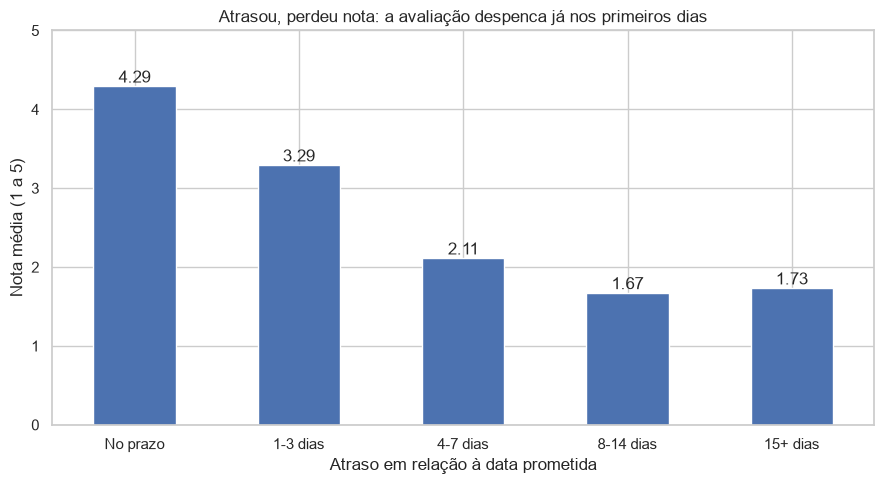

In [ ]:
ax = por_faixa["nota_media"].plot(kind="bar", figsize=(9, 5), color="#4C72B0")

ax.set_title("Atrasou, perdeu nota: a avaliação despenca já nos primeiros dias")
ax.set_xlabel("Atraso em relação à data prometida")
ax.set_ylabel("Nota média (1 a 5)")
ax.set_ylim(0, 5)
plt.xticks(rotation=0)

# rótulo com a nota em cima de cada barra
for i, v in enumerate(por_faixa["nota_media"]):
    ax.text(i, v + 0.05, f"{v:.2f}", ha="center")

plt.tight_layout()
plt.savefig("../reports/figures/01_nota_media_por_faixa.png", dpi=150, bbox_inches="tight")
plt.show()

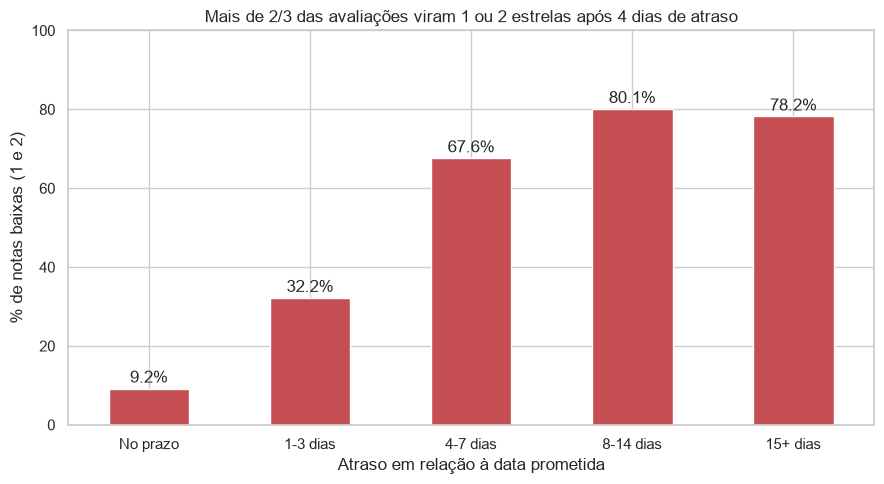

In [ ]:
ax = pct_baixa.plot(kind="bar", figsize=(9, 5), color="#C44E52")

ax.set_title("Mais de 2/3 das avaliações viram 1 ou 2 estrelas após 4 dias de atraso")
ax.set_xlabel("Atraso em relação à data prometida")
ax.set_ylabel("% de notas baixas (1 e 2)")
ax.set_ylim(0, 100)
plt.xticks(rotation=0)

for i, v in enumerate(pct_baixa):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center")

plt.tight_layout()
plt.savefig("../reports/figures/01_notas_baixas_por_faixa.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
total_baixas = df["nota_baixa"].sum()
baixas_atrasados = df.loc[df["atrasado"], "nota_baixa"].sum()
print(f"{baixas_atrasados / total_baixas * 100:.1f}% das notas baixas vêm de pedidos atrasados")

32.5% das notas baixas vêm de pedidos atrasados


## Insight e ação
Os atrasos são raros (6,7% dos pedidos entregues e avaliados), mas respondem por **32,5% de todas as notas baixas** (1 e 2 estrelas): uma em cada três avaliações ruins vem de um pedido que chegou depois do prazo prometido. O efeito começa cedo, já que com 1 a 3 dias de atraso a nota cai mais de 1 ponto, e a partir de 8 dias ela se estabiliza em torno de 1,7.

**Ação sugerida:** o maior ganho está em evitar os atrasos acima de 3 dias, que concentram as piores notas, e em prometer prazos mais realistas ao cliente. Prometer um prazo mais realista custa menos do que perder a avaliação.

## Limitações
- Correlação não implica causalidade: pedidos atrasados podem ter outros problemas associados (produto extraviado, vendedor com falhas) que também influenciam a nota.
- Atraso = entrega real posterior à data estimada. Foram considerados apenas pedidos `delivered`, e os pedidos com mais de uma avaliação usam a nota média.